In [81]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv(r'C:\Users\SuNi\Downloads\train_u6lujuX_CVtuZ9i (1).csv')
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [97]:
print(df.shape)
df.info()

(614, 12)
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    int64  
 1   Married            614 non-null    int64  
 2   Dependents         614 non-null    int64  
 3   Education          614 non-null    int64  
 4   Self_Employed      614 non-null    int64  
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         614 non-null    float64
 8   Loan_Amount_Term   614 non-null    float64
 9   Credit_History     614 non-null    float64
 10  Property_Area      614 non-null    int64  
 11  Loan_Status        614 non-null    int64  
dtypes: float64(4), int64(8)
memory usage: 57.7 KB


In [83]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [84]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [85]:
df = df.drop(['Loan_ID'], axis=1)
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


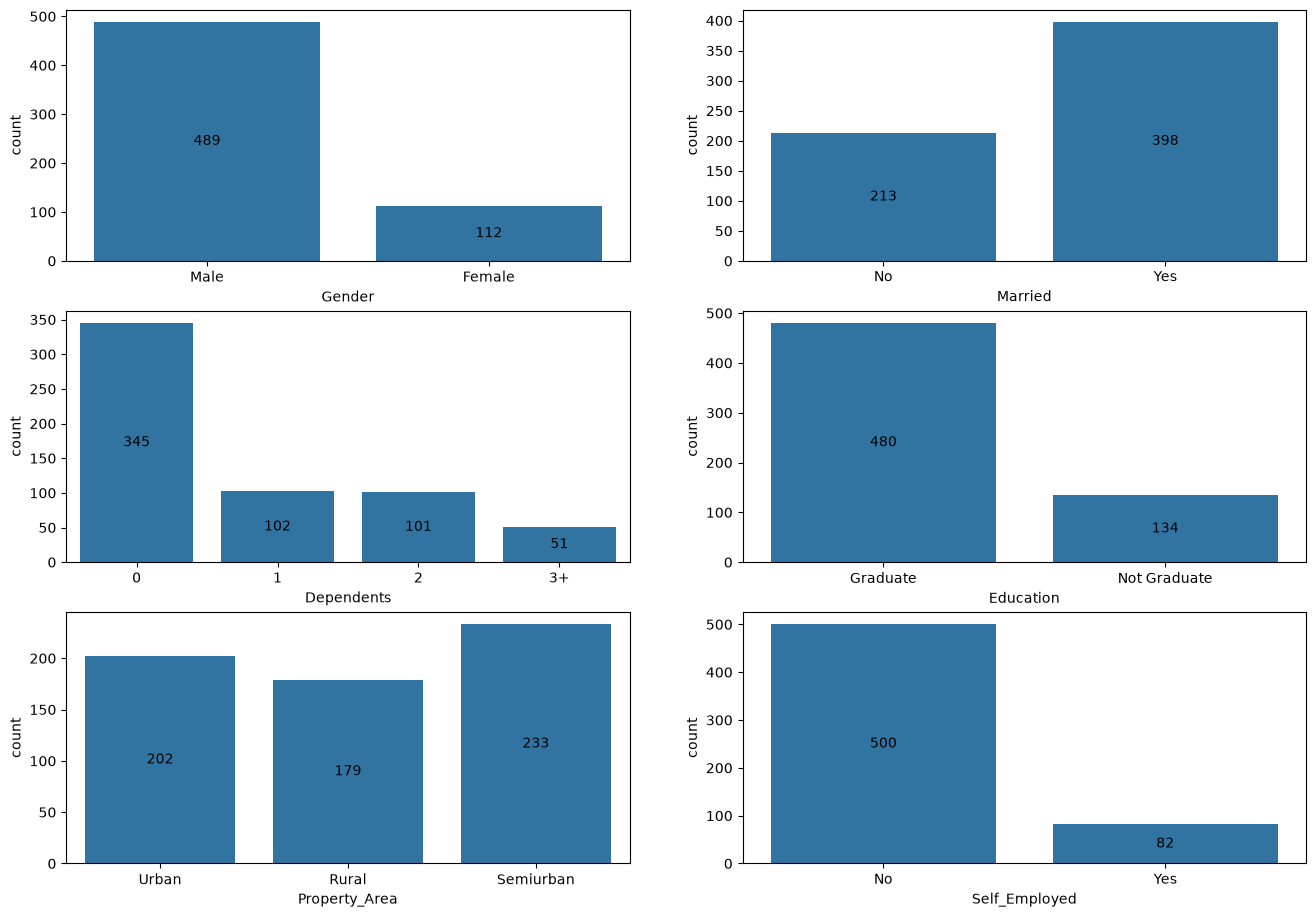

In [86]:
word_cols = ['Gender', 'Married', 'Dependents', 'Education', 'Property_Area', 'Self_Employed' ]

fig = plt.figure(figsize=(16, 15))

for idx, col in enumerate(word_cols):
    ax = plt.subplot(4, 2, idx+1)
    sns.countplot(x=df[col], ax=ax)
    for container in ax.containers:
        ax.bar_label(container, label_type='center')

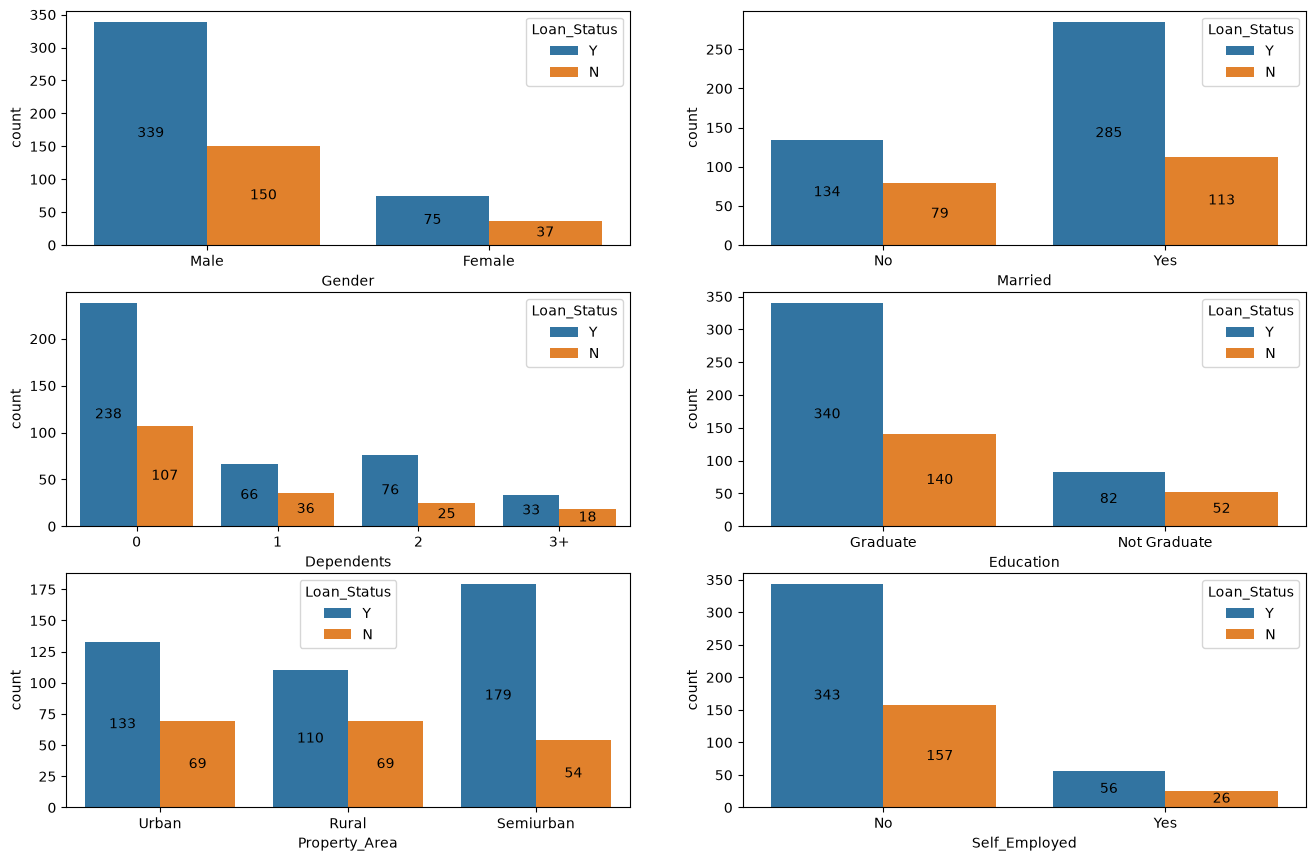

In [87]:
fig = plt.figure(figsize=(16, 14))

for idx, col in enumerate(word_cols):
    ax = plt.subplot(4, 2, idx+1)
    sns.countplot(x=df[col], hue=df['Loan_Status'], ax=ax)
    for container in ax.containers:
        ax.bar_label(container, label_type='center')

<Axes: xlabel='Credit_History', ylabel='count'>

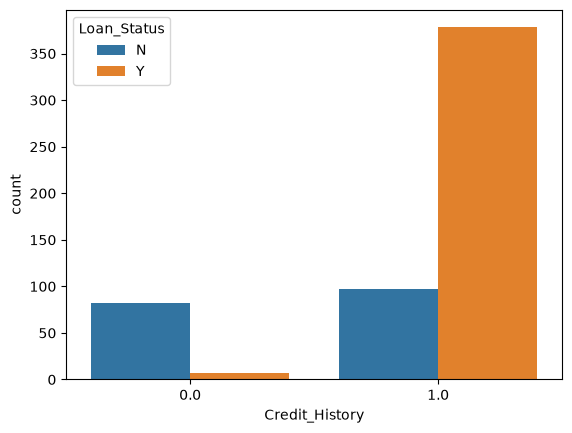

In [88]:
sns.countplot(data=df, x='Credit_History', hue='Loan_Status')

In [98]:
word_cols = ['Gender', 'Property_Area', 'Loan_Status', 'Married', 'Dependents', 'Self_Employed', 'Education']

for col in word_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())

encoders = {}
for col in word_cols:
    encoders[col] = LabelEncoder()
    df[col] = encoders[col].fit_transform(df[col].astype(str))

df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,2,1
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2,1


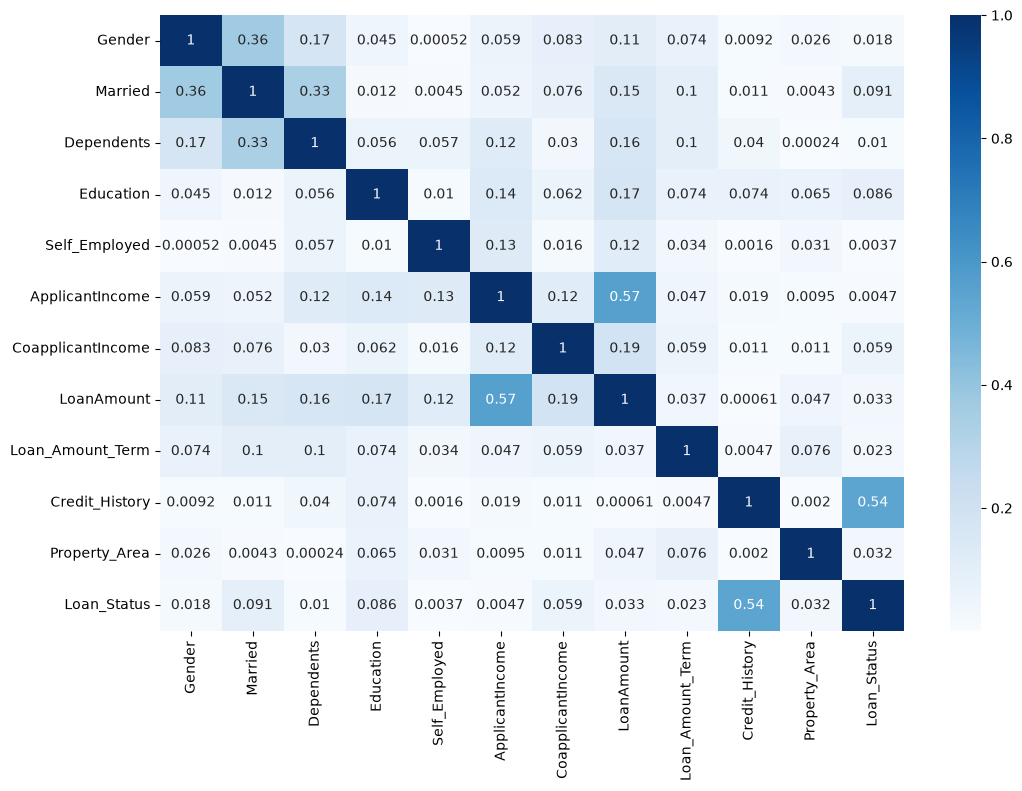

In [99]:
fig = plt.figure(figsize=(12, 8))

corr = abs(df.corr(numeric_only=True))
sns.heatmap(corr, annot=True, cmap='Blues')
plt.show()

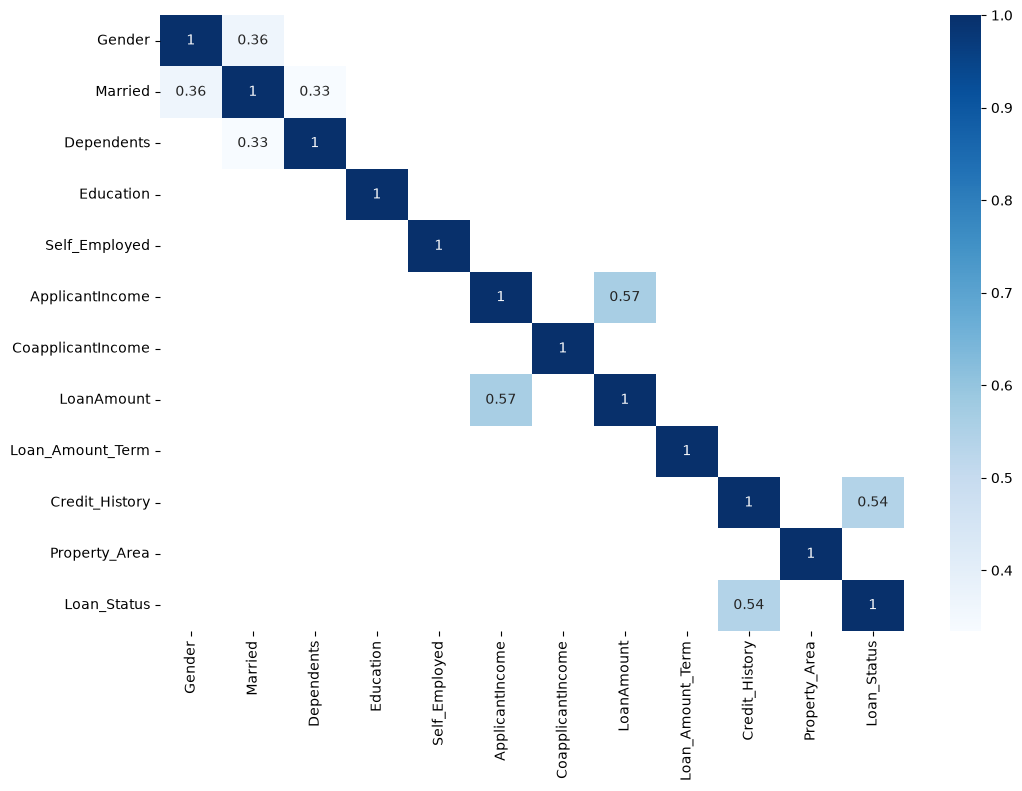

In [100]:
fig = plt.figure(figsize=(12, 8))
sns.heatmap(corr[(corr > 0.30) | (corr < -0.30)], annot=True, cmap='Blues')
plt.show()

In [101]:
X = df.drop(['Loan_Status'], axis=1)
y = df['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=1)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X)
X_train_scaled

array([[ 0.47234264, -1.37208932, -0.73780632, ...,  0.2732313 ,
         0.41173269,  1.22329839],
       [ 0.47234264,  0.72881553,  0.25346957, ...,  0.2732313 ,
         0.41173269, -1.31851281],
       [ 0.47234264,  0.72881553, -0.73780632, ...,  0.2732313 ,
         0.41173269,  1.22329839],
       ...,
       [ 0.47234264,  0.72881553,  0.25346957, ...,  0.2732313 ,
         0.41173269,  1.22329839],
       [ 0.47234264,  0.72881553,  1.24474546, ...,  0.2732313 ,
         0.41173269,  1.22329839],
       [-2.11710719, -1.37208932, -0.73780632, ...,  0.2732313 ,
        -2.42876026, -0.04760721]], shape=(614, 11))

In [102]:
models = {
    'Logistic Regression': LogisticRegression(),
    'Random Forest': RandomForestClassifier(),
    'K-Neighbors': KNeighborsClassifier(),
    'SVM': LinearSVC()
}

for name, m in models.items():
    m.fit(X_train, y_train)
    pred=m.predict(X_train)
    print(f'\n---{name}---')
    print(f"Overall Accuracy: {accuracy_score(y_train, pred):.4f}")
    print(f'Classification Report:\n{classification_report(y_train, pred)}')


---Logistic Regression---
Overall Accuracy: 0.8288
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.47      0.62       111
           1       0.81      0.98      0.89       257

    accuracy                           0.83       368
   macro avg       0.87      0.73      0.76       368
weighted avg       0.85      0.83      0.81       368


---Random Forest---
Overall Accuracy: 1.0000
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       111
           1       1.00      1.00      1.00       257

    accuracy                           1.00       368
   macro avg       1.00      1.00      1.00       368
weighted avg       1.00      1.00      1.00       368


---K-Neighbors---
Overall Accuracy: 0.7582
Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.31      0.43       111
           1       0.76   

In [103]:
models = {
    'Logistic Regression': LogisticRegression(),
    'Random Forest': RandomForestClassifier(),
    'K-Neighbors': KNeighborsClassifier(),
    'SVM': LinearSVC()
}

for name, m in models.items():
    m.fit(X_train, y_train)
    pred=m.predict(X_test)
    print(f'\n---{name}---')
    print(f"Overall Accuracy: {accuracy_score(y_test, pred):.4f}")
    print(f'Classification Report:\n{classification_report(y_test, pred)}')


---Logistic Regression---
Overall Accuracy: 0.7846
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.40      0.55        81
           1       0.77      0.98      0.86       165

    accuracy                           0.78       246
   macro avg       0.83      0.69      0.70       246
weighted avg       0.81      0.78      0.76       246


---Random Forest---
Overall Accuracy: 0.7724
Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.41      0.54        81
           1       0.77      0.95      0.85       165

    accuracy                           0.77       246
   macro avg       0.79      0.68      0.69       246
weighted avg       0.78      0.77      0.75       246


---K-Neighbors---
Overall Accuracy: 0.6382
Classification Report:
              precision    recall  f1-score   support

           0       0.37      0.14      0.20        81
           1       0.68   

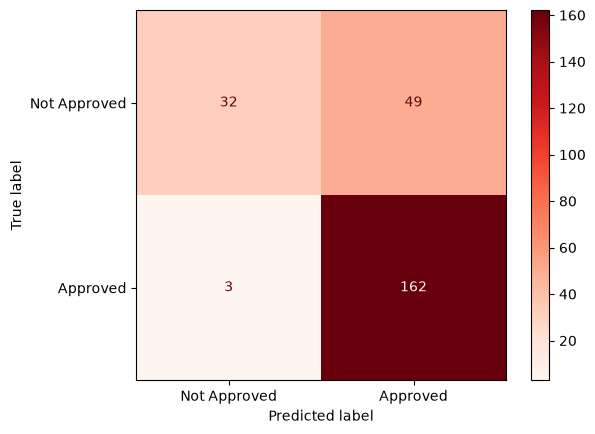

In [95]:
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=['Not Approved', 'Approved']).plot(cmap='Reds')
plt.show()
